In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Adult file data (first file)

In [4]:
ad_data=pd.read_csv('adult.csv')

In [5]:
ad_data

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


# Check and Drop Duplicates Records

In [6]:
ad_data.duplicated().sum()

np.int64(52)

In [7]:
ad_data.drop_duplicates(inplace=True)

In [8]:
ad_data.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


In [9]:
ad_data.workclass

0             Private
1             Private
2           Local-gov
3             Private
4                   ?
             ...     
48837         Private
48838         Private
48839         Private
48840         Private
48841    Self-emp-inc
Name: workclass, Length: 48790, dtype: str

In [10]:
(ad_data['workclass'] == '?').sum()

np.int64(2795)

In [11]:
ad_data['workclass']=ad_data['workclass'].replace('?',ad_data.workclass.mode()[0])

In [12]:
ad_data.workclass.unique()

<ArrowStringArray>
[         'Private',        'Local-gov', 'Self-emp-not-inc',
      'Federal-gov',        'State-gov',     'Self-emp-inc',
      'Without-pay',     'Never-worked']
Length: 8, dtype: str

In [13]:
ad_data['workclass'].value_counts()

workclass
Private             36655
Self-emp-not-inc     3861
Local-gov            3136
State-gov            1981
Self-emp-inc         1694
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

In [14]:
ad_data.info()


<class 'pandas.DataFrame'>
Index: 48790 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48790 non-null  int64
 1   workclass        48790 non-null  str  
 2   fnlwgt           48790 non-null  int64
 3   education        48790 non-null  str  
 4   educational-num  48790 non-null  int64
 5   marital-status   48790 non-null  str  
 6   occupation       48790 non-null  str  
 7   relationship     48790 non-null  str  
 8   race             48790 non-null  str  
 9   gender           48790 non-null  str  
 10  capital-gain     48790 non-null  int64
 11  capital-loss     48790 non-null  int64
 12  hours-per-week   48790 non-null  int64
 13  native-country   48790 non-null  str  
 14  income           48790 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.7 MB


In [15]:
ad_data.occupation.unique()

<ArrowStringArray>
['Machine-op-inspct',   'Farming-fishing',   'Protective-serv',
                 '?',     'Other-service',    'Prof-specialty',
      'Craft-repair',      'Adm-clerical',   'Exec-managerial',
      'Tech-support',             'Sales',   'Priv-house-serv',
  'Transport-moving', 'Handlers-cleaners',      'Armed-Forces']
Length: 15, dtype: str

In [16]:
ad_data['occupation'].value_counts()

occupation
Prof-specialty       6165
Craft-repair         6102
Exec-managerial      6082
Adm-clerical         5606
Sales                5501
Other-service        4919
Machine-op-inspct    3017
?                    2805
Transport-moving     2355
Handlers-cleaners    2071
Farming-fishing      1485
Tech-support         1445
Protective-serv       982
Priv-house-serv       240
Armed-Forces           15
Name: count, dtype: int64

In [17]:
(ad_data['occupation'] == '?').sum()

np.int64(2805)

In [18]:
ad_data.occupation.mode()

0    Prof-specialty
Name: occupation, dtype: str

In [19]:
ad_data.occupation=ad_data.occupation.replace('?',ad_data.occupation.mode()[0])

In [20]:
ad_data.relationship.unique()

<ArrowStringArray>
['Own-child', 'Husband', 'Not-in-family', 'Unmarried', 'Wife',
 'Other-relative']
Length: 6, dtype: str

In [21]:
ad_data.gender.value_counts()

gender
Male      32614
Female    16176
Name: count, dtype: int64

# Check NAN values and Fillna 

In [22]:
ad_data.isna().sum()

age                0
workclass          0
fnlwgt             0
education          0
educational-num    0
marital-status     0
occupation         0
relationship       0
race               0
gender             0
capital-gain       0
capital-loss       0
hours-per-week     0
native-country     0
income             0
dtype: int64

In [23]:
ad_data.workclass.mode()

0    Private
Name: workclass, dtype: str

In [24]:
ad_data.workclass.isna().sum()

np.int64(0)

In [25]:
ad_data.workclass=ad_data.workclass.fillna(ad_data.workclass.mode()[0])

# Graph, visualization, chart 

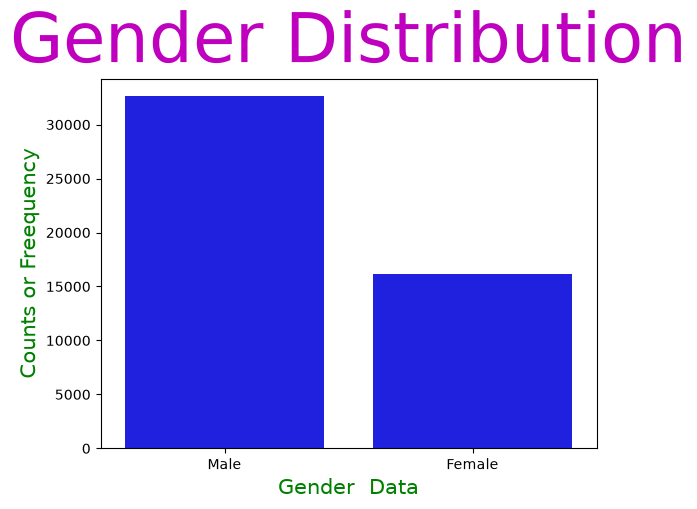

In [26]:
plt.title("Gender Distribution", fontdict={"size": 50, 'color': 'm'})
sns.barplot(x = ad_data.gender.value_counts().index, y =  ad_data.gender.value_counts().values, color = "b")
plt.xlabel("Gender  Data", fontdict={"size": 15, "color": "g"})
plt.ylabel("Counts or Freequency",fontdict={"size": 15, "color": "g"})
plt.show()

In [27]:
ad_data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'educational-num',
       'marital-status', 'occupation', 'relationship', 'race', 'gender',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='str')

In [28]:
ad_data

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,Private,103497,Some-college,10,Never-married,Prof-specialty,Own-child,White,Female,0,0,30,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
48838,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
48839,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
48840,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [29]:
 
x= ad_data.race.value_counts()
y = ad_data.race.value_counts().index

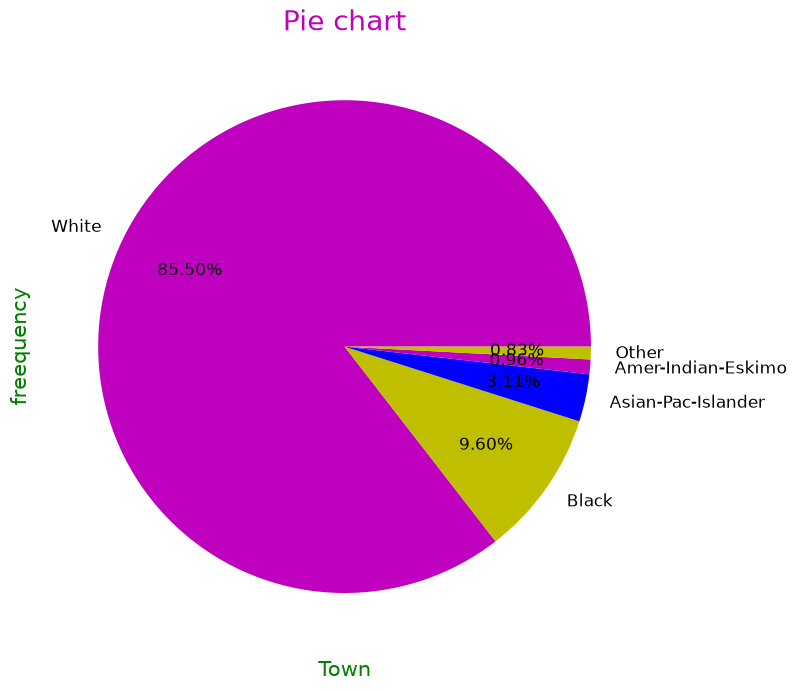

In [30]:
plt.figure(figsize=(8, 8))
plt.title("Pie chart", fontdict={"size": 20, 'color': "m"})
plt.pie(x = x, labels=y, autopct="%.2f%%",colors = ["m","y", "b"],textprops={"fontsize": 12},pctdistance=0.7,labeldistance=1.1)
plt.xlabel("Town",fontdict={"size": 15, "color": "g"})
plt.ylabel('freequency',fontdict={"size": 15, "color": "g"})
plt.show()

# Load Hotel Booking file data (2nd file)

In [6]:
data_hotel = pd.read_csv('hotel_booking.csv')

In [7]:
data_hotel.shape

(119390, 36)

In [8]:
data_hotel.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [34]:
data_hotel.head(5)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,Transient,0.0,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,Transient,75.0,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,Transient,98.0,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498


In [ ]:
data_hotel.reservation_status_date         

In [35]:
data_hotel.reservation_status_date=pd.to_datetime(data_hotel.reservation_status_date)

# Check NAN values and Fillna

In [46]:
data_hotel.isna().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces 

In [37]:
data_hotel.country.isna().sum()


np.int64(488)

In [38]:
data_hotel.country=data_hotel.country.fillna(data_hotel.country.mode()[0])

In [39]:
data_hotel.agent=data_hotel.agent.fillna(data_hotel.agent.mean())

In [40]:
data_hotel.drop('company', axis=1, inplace=True)

In [41]:
data_hotel.children=data_hotel.children.fillna(0.0)

# Check Duplicate values and Drop Duplicate

In [42]:
data_hotel.duplicated().sum()

np.int64(0)

In [43]:
data_hotel.drop_duplicates(inplace=True)

In [84]:
data_hotel.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'name', 'email',
       'phone-number', 'credit_card'],
      dtype='str')

# Graph and Visualization

<Axes: xlabel='agent'>

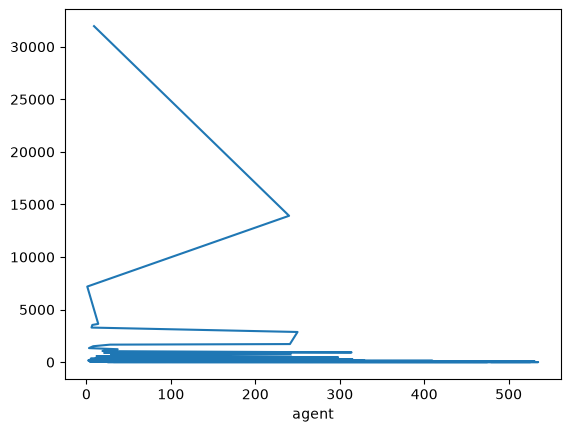

In [85]:
data_hotel.agent.value_counts().plot(kind = "line")

In [9]:
x= data_hotel.market_segment.value_counts()
y = data_hotel.market_segment.value_counts().index

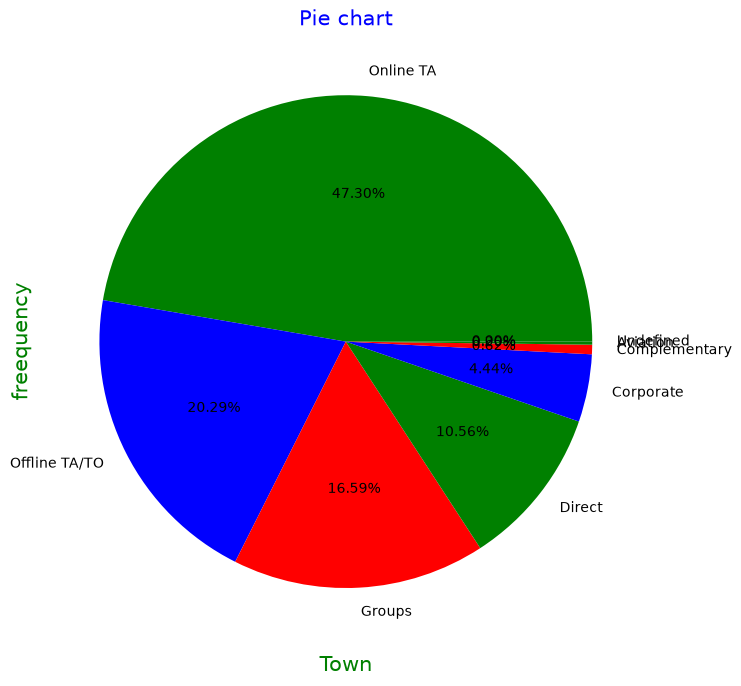

In [10]:
plt.figure(figsize=(8, 8))
plt.title("Pie chart", fontdict={"size": 15, 'color': "b"})
plt.pie(x = x, labels=y, autopct="%.2f%%",colors = ["g","b", "r"],textprops={"fontsize": 10},pctdistance=0.6,labeldistance=1.1)
plt.xlabel("Town",fontdict={"size": 15, "color": "g"})
plt.ylabel('freequency',fontdict={"size": 15, "color": "g"})
plt.show()

# Load Loan Train file data (3rd file)

In [11]:
lt_data = pd.read_csv('loan-train.csv')

In [13]:
lt_data.shape

(1614, 13)

In [14]:
lt_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   str    
 1   Gender             1601 non-null   str    
 2   Married            1611 non-null   str    
 3   Dependents         1599 non-null   str    
 4   Education          1614 non-null   str    
 5   Self_Employed      1582 non-null   str    
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1592 non-null   float64
 9   Loan_Amount_Term   1600 non-null   float64
 10  Credit_History     1564 non-null   float64
 11  Property_Area      1614 non-null   str    
 12  Loan_Status        1614 non-null   str    
dtypes: float64(4), int64(1), str(8)
memory usage: 221.3 KB


# Check NAN values and Fillna

In [68]:
lt_data.isna().sum()

Loan_ID               0
Gender               13
Married               0
Dependents            0
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
dtype: int64

In [44]:
lt_data.Dependents.unique()

array([0.       , 1.       , 2.       , 0.7816358])

In [40]:
lt_data.Dependents=lt_data.Dependents.astype('float')

In [41]:
lt_data.Dependents.dtype


dtype('float64')

In [43]:
lt_data.Dependents=lt_data.Dependents.fillna(lt_data.Dependents.mean())

In [50]:
lt_data.Self_Employed.unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

In [49]:
lt_data.Self_Employed=lt_data.Self_Employed.fillna(lt_data.Self_Employed.mode()[0])

In [52]:
lt_data.LoanAmount.unique()

array([ nan, 128.,  66., 120., 141., 267.,  95., 158., 168., 349.,  70.,
       109., 200., 114.,  17., 125., 100.,  76., 133., 115., 104., 315.,
       116., 112., 151., 191., 122., 110.,  35., 201.,  74., 106., 320.,
       144., 184.,  80.,  47.,  75., 134.,  96.,  88.,  44., 286.,  97.,
       135., 180.,  99., 165., 258., 126., 312., 136., 172.,  81., 187.,
       113., 176., 130., 111., 167., 265.,  50., 210., 175., 131., 188.,
        25., 137., 160., 225., 216.,  94., 139., 152., 118., 185., 154.,
        85., 259., 194.,  93., 370., 182., 650., 102., 290.,  84., 242.,
       129.,  30., 244., 600., 255.,  98., 275., 121.,  63., 700.,  87.,
       101., 495.,  67.,  73., 260., 108.,  58.,  48., 164., 170.,  83.,
        90., 166., 124.,  55.,  59., 127., 214., 240.,  72.,  60., 138.,
        42., 280., 140., 155., 123., 279., 192., 304., 330., 150., 207.,
       436.,  78.,  54.,  89., 143., 105., 132., 480.,  56., 159., 300.,
       376., 117.,  71., 490., 173.,  46., 228., 30

In [56]:
lt_data.LoanAmount=lt_data.LoanAmount.fillna(lt_data.LoanAmount.mean())

In [58]:
lt_data.Loan_Amount_Term.unique()

array([360., 120., 240.,  nan, 180.,  60., 300., 480.,  36.,  84.,  12.])

In [59]:
lt_data.Loan_Amount_Term=lt_data.Loan_Amount_Term.fillna(lt_data.Loan_Amount_Term.mean())

In [61]:
lt_data.Credit_History.unique()

array([ 1.,  0., nan])

In [62]:
lt_data.Credit_History.mean()

np.float64(0.6355498721227621)

In [63]:
lt_data.Credit_History=lt_data.Credit_History.fillna(lt_data.Credit_History.mean())

In [65]:
lt_data.Married.unique()


<ArrowStringArray>
['No', 'Yes', nan]
Length: 3, dtype: str

In [66]:
lt_data.Married.mode()

0    Yes
Name: Married, dtype: str

In [67]:
lt_data.Married=lt_data.Married.fillna(lt_data.Married.mode()[0])

# Check Duplicate values and Drop Duplicate

In [70]:
lt_data.duplicated

<bound method DataFrame.duplicated of        Loan_ID  Gender Married  Dependents     Education Self_Employed  \
0     LP001002    Male      No    0.000000      Graduate            No   
1     LP001003    Male     Yes    1.000000      Graduate            No   
2     LP001005    Male     Yes    0.000000      Graduate           Yes   
3     LP001006    Male     Yes    0.000000  Not Graduate            No   
4     LP001008    Male      No    0.000000      Graduate            No   
...        ...     ...     ...         ...           ...           ...   
1609  LP009965    Male      No    0.781636      Graduate           Yes   
1610  LP009966    Male     Yes    0.000000      Graduate            No   
1611  LP009970    Male     Yes    0.781636  Not Graduate           Yes   
1612  LP009977  Female     Yes    2.000000      Graduate           Yes   
1613  LP009996  Female     Yes    2.000000      Graduate            No   

      ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \

In [71]:
lt_data.duplicated().sum()

np.int64(0)

In [72]:
lt_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0.000000,Graduate,No,5849,0.0,218.846734,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1.000000,Graduate,No,4583,1508.0,128.000000,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0.000000,Graduate,Yes,3000,0.0,66.000000,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0.000000,Not Graduate,No,2583,2358.0,120.000000,360.0,1.0,Urban,Y
4,LP001008,Male,No,0.000000,Graduate,No,6000,0.0,141.000000,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1609,LP009965,Male,No,0.781636,Graduate,Yes,13658,9822.0,323.000000,180.0,0.0,Urban,N
1610,LP009966,Male,Yes,0.000000,Graduate,No,13683,2223.0,182.000000,360.0,1.0,Semiurban,Y
1611,LP009970,Male,Yes,0.781636,Not Graduate,Yes,19409,768.0,222.000000,360.0,0.0,Urban,N
1612,LP009977,Female,Yes,2.000000,Graduate,Yes,8997,1354.0,355.000000,360.0,0.0,Rural,Y


# Chart and visualization

In [74]:
x= lt_data.Gender.value_counts()
y = lt_data.Gender.value_counts().index

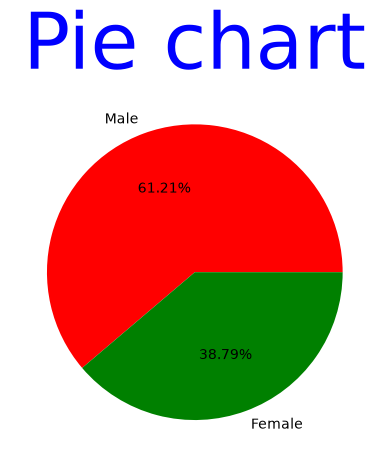

In [83]:
plt.title("Pie chart", fontdict={"size": 56, 'color': "b"})
plt.pie(x = x, labels=y, autopct="%.2f%%",colors = ["r","g", "b"])
plt.show()

<Axes: xlabel='LoanAmount'>

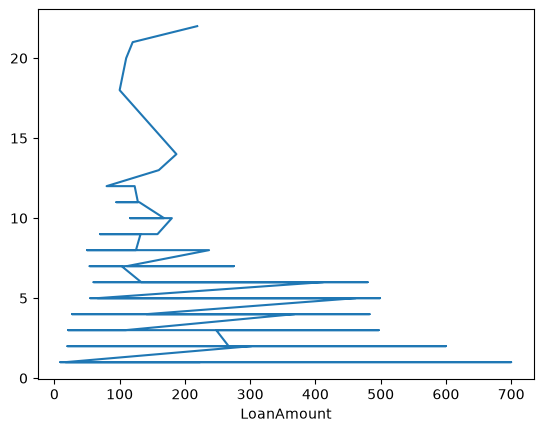

In [82]:
lt_data.LoanAmount.value_counts().plot(kind = "line")